ChurnGuard Project

In [ ]:
print("ChurnGuard project started")

ChurnGuard project started


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving churnguard_data (1).csv to churnguard_data (1).csv


In [ ]:
import pandas as pd

df = pd.read_csv("churnguard_data (1).csv")

df.head()

,customerID,gender,SeniorCitizen,tenure,PhoneService,InternetService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,CUST-0032,Male,0,21.0,YES,Fiber optic,Month-to-month,No,Credit card,29.73,600.01,Yes
1,CUST-0110,Male,0,55.0,YES,Fiber optic,Two year,Yes,Bank transfer,46.32,2515.48,No
2,CUST-0137,Female,1,46.0,Yes,Fiber optic,Month-to-month,No,Mailed check,87.06,4153.97,Yes
3,CUST-0089,Female,1,63.0,Yes,Fiber optic,Month-to-month,YES,Mailed check,56.97,3641.3,Yes
4,CUST-0919,Female,0,8.0,Yes,DSl,month to month,No,Electronic check,39.69,309.79,Yes


In [ ]:
print(df.shape)

(1030, 12)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        1030 non-null   object 
 1   gender            1030 non-null   object 
 2   SeniorCitizen     1030 non-null   int64  
 3   tenure            980 non-null    float64
 4   PhoneService      1030 non-null   object 
 5   InternetService   1014 non-null   object 
 6   Contract          1030 non-null   object 
 7   PaperlessBilling  1030 non-null   object 
 8   PaymentMethod     1030 non-null   object 
 9   MonthlyCharges    955 non-null    float64
 10  TotalCharges      966 non-null    object 
 11  Churn             1030 non-null   object 
dtypes: float64(2), int64(1), object(9)
memory usage: 96.7+ KB


In [ ]:
df.isna().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
tenure,50
PhoneService,0
InternetService,16
Contract,0
PaperlessBilling,0
PaymentMethod,0
MonthlyCharges,75


In [ ]:
df.duplicated().sum()

np.int64(30)

In [ ]:
df["Churn"].value_counts()

,count
Churn,
No,598
Yes,278
NO,38
no,38
nO,27
yEs,20
YES,20
yes,11


In [ ]:
df["Contract"].unique()

array(['Month-to-month', 'Two year', 'month to month', 'One year',
       'month-to-month', 'Monthly', 'Two Year', '1 year', '2 year',
       'two year', 'One Year', 'one year'], dtype=object)

In [ ]:
clean_df = df.copy()

print(clean_df.shape)

(1030, 12)


In [ ]:
clean_df = clean_df.drop(columns=["customerID"])

print(clean_df.shape)

(1030, 11)


In [ ]:
clean_df = clean_df.drop_duplicates()

print(clean_df.shape)

(1000, 11)


In [ ]:
clean_df["gender"] = clean_df["gender"].str.strip()
clean_df["PaymentMethod"] = clean_df["PaymentMethod"].str.strip()

print(clean_df["gender"].unique())
print(clean_df["PaymentMethod"].unique())

['Male' 'Female']
['Credit card' 'Bank transfer' 'Mailed check' 'Electronic check']


In [ ]:
clean_df["Churn"] = clean_df["Churn"].str.strip().str.title()
clean_df["PhoneService"] = clean_df["PhoneService"].str.strip().str.title()
clean_df["PaperlessBilling"] = clean_df["PaperlessBilling"].str.strip().str.title()

print(clean_df["Churn"].value_counts())
print(clean_df["PhoneService"].unique())
print(clean_df["PaperlessBilling"].unique())

Churn
No     682
Yes    318
Name: count, dtype: int64
['Yes' 'No']
['No' 'Yes']


In [ ]:
contract_map = {
    "month-to-month": "Month-to-month",
    "month to month": "Month-to-month",
    "monthly": "Month-to-month",
    "one year": "One year",
    "1 year": "One year",
    "two year": "Two year",
    "2 year": "Two year"
}

clean_df["Contract"] = (
    clean_df["Contract"]
    .str.strip()
    .str.lower()
    .map(contract_map)
)

print(clean_df["Contract"].value_counts(dropna=False))

Contract
Month-to-month    584
One year          229
Two year          187
Name: count, dtype: int64


In [ ]:
print(clean_df["InternetService"].value_counts(dropna=False))

InternetService
Fiber optic    336
DSL            317
No             185
Fibre optic     31
fiber optic     24
dsl             21
DSl             19
FiberOptic      17
NaN             16
Dsl             15
NO              13
no               6
Name: count, dtype: int64


In [ ]:
internet_map = {
    "dsl": "DSL",
    "fiber optic": "Fiber optic",
    "fibre optic": "Fiber optic",
    "fiberoptic": "Fiber optic",
    "no": "No"
}

clean_df["InternetService"] = (
    clean_df["InternetService"]
    .str.strip()
    .str.lower()
    .map(internet_map)
)

print(clean_df["InternetService"].value_counts(dropna=False))

InternetService
Fiber optic    408
DSL            372
No             204
NaN             16
Name: count, dtype: int64


In [ ]:
clean_df["InternetService"] = clean_df["InternetService"].fillna("No")

print(clean_df["InternetService"].value_counts(dropna=False))

InternetService
Fiber optic    408
DSL            372
No             220
Name: count, dtype: int64


In [ ]:
clean_df["TotalCharges"] = pd.to_numeric(
    clean_df["TotalCharges"], errors="coerce"
)

print(clean_df["TotalCharges"].dtype)
print(clean_df["TotalCharges"].isna().sum())

float64
98


In [ ]:
invalid_tenure = clean_df["tenure"] <= 0

print("Rows to remove:", invalid_tenure.sum())

clean_df = clean_df.loc[~invalid_tenure].copy()

print("Remaining shape:", clean_df.shape)

Rows to remove: 12
Remaining shape: (988, 11)


In [ ]:
invalid_charges = (
    (clean_df["MonthlyCharges"] < 10) |
    (clean_df["MonthlyCharges"] > 200)
)

print("Rows to remove:", invalid_charges.sum())

clean_df = clean_df.loc[~invalid_charges].copy()

print("Remaining shape:", clean_df.shape)

Rows to remove: 8
Remaining shape: (980, 11)


In [ ]:
monthly_mean = clean_df["MonthlyCharges"].mean()

clean_df["MonthlyCharges"] = (
    clean_df["MonthlyCharges"].fillna(monthly_mean)
)

print("Mean used:", monthly_mean)
print("Missing remaining:", clean_df["MonthlyCharges"].isna().sum())

Mean used: 65.18706593406594
Missing remaining: 0


In [ ]:
total_mean = clean_df["TotalCharges"].mean()

clean_df["TotalCharges"] = (
    clean_df["TotalCharges"].fillna(total_mean)
)

print("Mean used:", total_mean)
print("Missing remaining:", clean_df["TotalCharges"].isna().sum())

Mean used: 2326.624609286523
Missing remaining: 0


In [ ]:
tenure_median = round(clean_df["tenure"].median())

clean_df["tenure"] = (
    clean_df["tenure"].fillna(tenure_median).astype(int)
)

print("Median used:", tenure_median)
print("Missing remaining:", clean_df["tenure"].isna().sum())

Median used: 37
Missing remaining: 0


In [ ]:
print("Cleaned shape:", clean_df.shape)
print(clean_df.isna().sum())

Cleaned shape: (980, 11)
gender              0
SeniorCitizen       0
tenure              0
PhoneService        0
InternetService     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [ ]:
clean_df.to_csv("churnguard_clean.csv", index=False)

files.download("churnguard_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
churn_percentage = (
    clean_df["Churn"].value_counts(normalize=True) * 100
)

print(churn_percentage.round(2))

Churn
No     68.27
Yes    31.73
Name: proportion, dtype: float64


In [ ]:
contract_churn = pd.crosstab(
    clean_df["Contract"],
    clean_df["Churn"],
    normalize="index"
) * 100

print(contract_churn.round(2))

Churn              No    Yes
Contract                    
Month-to-month  52.55  47.45
One year        87.72  12.28
Two year        92.90   7.10


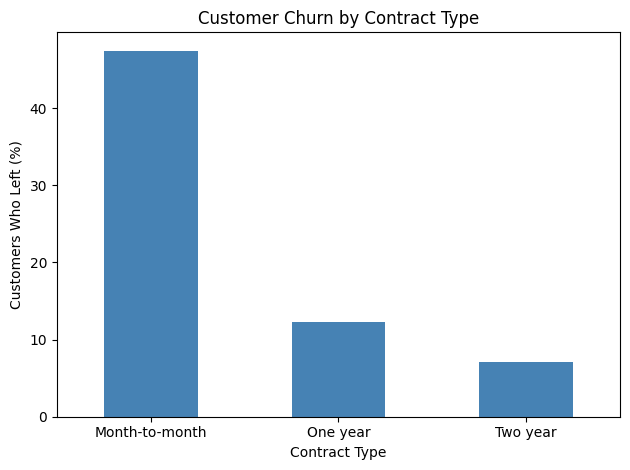

In [ ]:
import matplotlib.pyplot as plt

contract_churn["Yes"].plot(kind="bar", color="steelblue")

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Customers Who Left (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
internet_churn = pd.crosstab(
    clean_df["InternetService"],
    clean_df["Churn"],
    normalize="index"
) * 100

print(internet_churn.round(2))

Churn               No    Yes
InternetService              
DSL              71.39  28.61
Fiber optic      66.75  33.25
No               65.73  34.27


In [ ]:
churn_averages = clean_df.groupby("Churn")[
    ["tenure", "MonthlyCharges"]
].mean()

print(churn_averages.round(2))

       tenure  MonthlyCharges
Churn                        
No      36.17           63.88
Yes     36.26           67.99


In [ ]:
model_df = clean_df.copy()

model_df["Churn"] = model_df["Churn"].map({
    "Yes": 1,
    "No": 0
})

print(model_df["Churn"].value_counts())

Churn
0    669
1    311
Name: count, dtype: int64


In [ ]:
categorical_columns = [
    "gender",
    "PhoneService",
    "InternetService",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

model_df = pd.get_dummies(
    model_df,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

print(model_df.head())
print("Shape:", model_df.shape)

   SeniorCitizen  tenure  MonthlyCharges  TotalCharges  Churn  gender_Male  \
0              0      21           29.73        600.01      1            1   
1              0      55           46.32       2515.48      0            1   
2              1      46           87.06       4153.97      1            0   
3              1      63           56.97       3641.30      1            0   
4              0       8           39.69        309.79      1            0   

   PhoneService_Yes  InternetService_Fiber optic  InternetService_No  \
0                 1                            1                   0   
1                 1                            1                   0   
2                 1                            1                   0   
3                 1                            1                   0   
4                 1                            0                   0   

   Contract_One year  Contract_Two year  PaperlessBilling_Yes  \
0                  0             

In [ ]:
X = model_df.drop(columns=["Churn"])
y = model_df["Churn"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (980, 14)
y shape: (980,)


In [ ]:
numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

for column in numeric_columns:
    X[column] = pd.to_numeric(
        df.loc[X.index, column], errors="coerce"
    )

print(X[numeric_columns].isna().sum())

tenure            49
MonthlyCharges    70
TotalCharges      97
dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (784, 14)
Testing: (196, 14)


In [ ]:
fill_values = {
    "tenure": round(X_train["tenure"].median()),
    "MonthlyCharges": X_train["MonthlyCharges"].mean(),
    "TotalCharges": X_train["TotalCharges"].mean()
}

X_train = X_train.fillna(fill_values)
X_test = X_test.fillna(fill_values)

print("Training missing:", X_train.isna().sum().sum())
print("Testing missing:", X_test.isna().sum().sum())

Training missing: 0
Testing missing: 0


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training shape: (784, 14)
Testing shape: (196, 14)


In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

print("Model training completed")

Model training completed


In [ ]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy (%):", round(accuracy * 100, 2))

Accuracy (%): 68.88


In [ ]:
majority_class = y_train.mode()[0]

baseline_pred = [majority_class] * len(y_test)

baseline_accuracy = accuracy_score(y_test, baseline_pred)

print("Baseline accuracy (%):", round(baseline_accuracy * 100, 2))
print("Model accuracy (%):", round(accuracy * 100, 2))

Baseline accuracy (%): 68.37
Model accuracy (%): 68.88


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Stay", "Churn"],
    zero_division=0
))

              precision    recall  f1-score   support

        Stay       0.74      0.84      0.79       134
       Churn       0.51      0.35      0.42        62

    accuracy                           0.69       196
   macro avg       0.63      0.60      0.60       196
weighted avg       0.67      0.69      0.67       196



In [ ]:
from sklearn.metrics import confusion_matrix

results = pd.DataFrame(
    confusion_matrix(y_test, y_pred, labels=[0, 1]),
    index=["Actual Stay", "Actual Churn"],
    columns=["Predicted Stay", "Predicted Churn"]
)

print(results)

              Predicted Stay  Predicted Churn
Actual Stay              113               21
Actual Churn              40               22


In [ ]:
prediction_X = X[
    ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
].copy()

prediction_X["Contract"] = clean_df["Contract"].map({
    "Month-to-month": 0,
    "One year": 1,
    "Two year": 2
})

print(prediction_X.shape)

(980, 5)


In [ ]:
five_train = prediction_X.loc[X_train.index].copy()
five_test = prediction_X.loc[X_test.index].copy()

five_train = five_train.fillna(fill_values)
five_test = five_test.fillna(fill_values)

print("Training:", five_train.shape)
print("Testing:", five_test.shape)
print("Missing:", five_train.isna().sum().sum(),
      five_test.isna().sum().sum())

Training: (784, 5)
Testing: (196, 5)
Missing: 0 0


In [ ]:
five_scaler = StandardScaler()

five_train_scaled = five_scaler.fit_transform(five_train)
five_test_scaled = five_scaler.transform(five_test)

print("Training:", five_train_scaled.shape)
print("Testing:", five_test_scaled.shape)

Training: (784, 5)
Testing: (196, 5)


In [ ]:
five_model = LogisticRegression(max_iter=1000)
five_model.fit(five_train_scaled, y_train)

five_pred = five_model.predict(five_test_scaled)

print("Accuracy (%):",
      round(accuracy_score(y_test, five_pred) * 100, 2))

print(classification_report(
    y_test,
    five_pred,
    labels=[0, 1],
    target_names=["Stay", "Churn"],
    zero_division=0
))

Accuracy (%): 71.43
              precision    recall  f1-score   support

        Stay       0.75      0.88      0.81       134
       Churn       0.58      0.35      0.44        62

    accuracy                           0.71       196
   macro avg       0.66      0.62      0.62       196
weighted avg       0.69      0.71      0.69       196



In [ ]:
final_X = prediction_X.fillna({
    "tenure": round(prediction_X["tenure"].median()),
    "MonthlyCharges": prediction_X["MonthlyCharges"].mean(),
    "TotalCharges": prediction_X["TotalCharges"].mean()
})

final_scaler = StandardScaler()
final_X_scaled = final_scaler.fit_transform(final_X)

final_model = LogisticRegression(max_iter=1000)
final_model.fit(final_X_scaled, y)

print("Final model trained on", len(final_X), "records")

Final model trained on 980 records


In [ ]:
tenure = int(input("Enter tenure (months): "))
monthly = float(input("Enter Monthly Charges: "))
total = float(input("Enter Total Charges: "))
senior = int(input("Senior Citizen? (1 = Yes, 0 = No): "))
contract = int(input(
    "Contract type (0 = Month-to-month, 1 = One year, 2 = Two year): "
))

Enter tenure (months): 12
Enter Monthly Charges: 65.50
Enter Total Charges: 1500
Senior Citizen? (1 = Yes, 0 = No): 0
Contract type (0 = Month-to-month, 1 = One year, 2 = Two year): 0


In [ ]:
customer = pd.DataFrame([{
    "tenure": tenure,
    "MonthlyCharges": monthly,
    "TotalCharges": total,
    "SeniorCitizen": senior,
    "Contract": contract
}])

customer_scaled = final_scaler.transform(customer)

prediction = final_model.predict(customer_scaled)[0]

if prediction == 1:
    print("Prediction: This customer is likely to CHURN.")
else:
    print("Prediction: This customer is likely to STAY.")

Prediction: This customer is likely to STAY.


### ChurnGuard — Project Summary and Findings

**Purpose**

This project analyzes telecom customer data to understand patterns associated with customers leaving, called customer churn. It also builds a model to predict whether a customer might stay or leave.

**Work completed**

- Explored 1,030 records and 12 columns.
- Removed 30 duplicate rows and the customer ID column.
- Standardized text labels, converted total charges into numbers, and handled missing values.
- Removed 12 records with non-positive tenure and 8 with monthly charges outside the assignment’s allowed range.
- Retained 980 records and 11 columns for analysis.
- Compared customer groups and visualized churn by contract type.

**Main findings**

- Overall, **31.73%** of records in the cleaned dataset had Churn = Yes.
- Churn was **47.45%** for month-to-month contracts, **12.28%** for one-year contracts, and **7.10%** for two-year contracts.
- Customers who left had average monthly charges of **67.99**, compared with **63.88** for those who stayed.
- Average tenure was similar: **36.26 months** for customers who left and **36.17 months** for those who stayed.

**Prediction models**

Logistic Regression was evaluated using 80% training data and 20% test data. Numeric missing-value replacements and scaling rules were learned from training data only.

- Always predicting Stay achieved **68.37% accuracy**.
- The 14-feature model achieved **68.88% accuracy**.
- The five-feature model achieved **71.43% accuracy**, with approximately **58% churn precision** and **35% churn recall**.

A final five-feature demonstration model was then trained on all 980 records to accept manually entered customer details.

**Business usefulness and limitations**

The analysis can help a company prioritize investigation and test retention actions, particularly for month-to-month customers. These patterns do not prove why customers left.

The five-feature model missed about 65% of actual churners in the test set, so its predictions have limited reliability. The results come from one test split, and some analysis values were estimated through missing-value replacement. No reduction in churn or revenue improvement was measured.
